# A5 (Pro版)：匝道汇入场景 (On-Ramp Merge) —— 横纵向协同规划与高阶平滑换道闭环

> **诚实声明**：本实验为纯 Python 运动学模型演示，未调用 esmini、SUMO 等仿真引擎；主路车流为脚本设定的匀速运动，轨迹与评价指标均由运动学模型积分计算得出。

> **实验定位**：本实验属于智能电动汽车（IEV）虚拟仿真体系 **链2：智能驾驶算法闭环**。
> 聚焦高速公路与城市快速路匝道汇入这一典型高难度交互工况，攻关加速车道长度受限、主路车流穿插间隙动态变化的挑战，设计并验证**具备纵向安全间距协同与横向五次多项式无冲击 (Jerk-Free) 平滑换道的全自主汇入闭环系统**。

---

### ⏱️ 3分钟极速上手指南
* **第一步 (环境自检)**：执行阶段一，载入车辆运动学模型与匝道汇入拓扑定义，确认环境就绪；
* **第二步 (算法拆解)**：学习横纵向解耦与协同控制原理 —— 纵向间距环速度微调，横向高阶多项式轨迹规划；
* **第三步 (闭环测试)**：运行匝道加速与协同并道闭环仿真，观测自车以 $12\,\text{m/s}$ 初速加速并平滑切入 $14\,\text{m/s}$ 主路车流的完整过程；
* **第四步 (动态回放)**：通过 2D 鸟瞰路面快照、四合一遥测图表与交互式 Canvas 高速公路动效回放器，直观体察汇入时空演变；
* **第五步 (参数对比)**：对比传统硬突变换道与高阶平滑换道的横向加加速度（Jerk）差异，并在学生动手区调节汇入激进度；
* **第六步 (官方评分)**：一键执行自动评分，落盘评测结果并获取 100/100 成绩单。

---

### 📚 核心理论与工程背景：匝道汇入的横纵向协同控制

1. **场景空间拓扑与控制目标 (Ramp Topology & Objectives)**：
   * **主路车道 (Mainline Lane)**：位于 $Y = 0.0\,\text{m}$，主路车辆以 $14.0\,\text{m/s}$ 匀速巡航；
   * **加速车道/匝道 (On-Ramp Acceleration Lane)**：自车初始位于 $Y = -3.5\,\text{m}$，初始车速 $12.0\,\text{m/s}$；
   * **控制目标**：在有限汇入区间内，纵向消除与主路车辆的速度差并保持安全时距（$T_{\text{headway}} \ge 1.0\,\text{s}$），横向平顺由 $Y = -3.5\,\text{m}$ 过渡至 $Y = 0.0\,\text{m}$，侧向冲击度最小化。

2. **纵向跟驰与车隙插入 (Longitudinal Gap Acceptance)**：
   自车与主路领航车的期望车间距满足恒定时头距模型：
   $$d_{\text{des}} = d_0 + v_{\text{ego}} \cdot T_{\text{gap}} \quad (d_0 = 5.0\,\text{m}, T_{\text{gap}} = 1.0\,\text{s})$$
   纵向加速度控制器结合间隙误差与相对速度进行反馈调节：
   $$a_{\text{cmd}} = \text{clip}\Big(k_p \cdot (d_{\text{act}} - d_{\text{des}}) + k_d \cdot (v_{\text{lead}} - v_{\text{ego}}),\, -3.0,\, 2.0\Big)$$

3. **横向五次多项式平滑轨迹 (Quintic Polynomial Smooth Lateral Shift)**：
   传统阶跃转向会导致横向加加速度（Jerk）暴增，乘员产生剧烈眩晕感。
   采用五次多项式（Quintic Polynomial）规划横向位移 $y(\tau)$，满足起点与终点位置、速度、加速度均为 0 的平滑边界条件：
   $$y(\tau) = y_{\text{start}} + (y_{\text{end}} - y_{\text{start}}) \cdot \left( 10\tau^3 - 15\tau^4 + 6\tau^5 \right) \quad \left(\tau = \frac{t - t_{\text{start}}}{T_{\text{merge}}} \in [0, 1]\right)$$
   * 导数 $\dot{y}(\tau)$ 在端点平滑归零，无突变侧向力；
   * 二阶导 $\ddot{y}(\tau)$（侧向加速度）连续，彻底消除侧向冲击！



In [1]:
# 阶段一：环境自检与车辆运动学模型准备
import sys, os, math
sys.dont_write_bytecode = True

# 1. 稳健的多路径导入保障
for p in ['/home/jovyan/labs', os.path.abspath('../labs'), os.path.abspath('labs')]:
    if os.path.exists(p) and p not in sys.path:
        sys.path.insert(0, p)
        break

import matplotlib.pyplot as plt
from common.controller import BaseController
from common.esmini_env import KinematicBicycleModel
from common.vehicle_library import load_vehicle

# 2. 从标准车辆库载入参数（链1：车型设计 -> 链2：智能驾驶）
veh_params = load_vehicle('bev_sedan')
l_wb = veh_params['kinematic']['l_f'] + veh_params['kinematic']['l_r']
print(f"✓ 实验车型加载成功: {veh_params['name']} (整备质量: {veh_params['mass_kg']} kg)")
print(f"  运动学轴距 L = {l_wb:.2f} m, 转向角极限 = {veh_params['kinematic']['max_steer_deg']}°")

# 3. 几何车道常量标定
Y_MAIN = 0.0    # 主路中心线 Y 坐标 (m)
Y_RAMP = -3.5   # 匝道中心线 Y 坐标 (m)

print(f"✓ 汇入几何定义: 匝道 Y = {Y_RAMP} m -> 主路 Y = {Y_MAIN} m")
print("✓ 平台环境就绪")


✓ 实验车型加载成功: 标准纯电轿车 (整备质量: 1800 kg)
  运动学轴距 L = 2.80 m, 转向角极限 = 30°
✓ 汇入几何定义: 匝道 Y = -3.5 m -> 主路 Y = 0.0 m
✓ 平台环境就绪


## 阶段二：横纵向协同汇入控制器设计 | Controller Implementation

控制器核心架构：
1. **纵向速度与间距调节**：自车在匝道阶段对齐主路车流速度，并在检测到安全车头时距时保持稳定巡航；
2. **横向五次多项式导引**：在选定汇入时刻激活高阶平滑轨迹发生器，计算期望横向位置 $y_{\text{ref}}$ 与前轮转角 $\delta$；
3. **支持平滑模式 (Quintic) 与基线硬并道模式 (Step)**：用于后续进行乘员舒适度与冲击度量化对比。


In [2]:
class AdvancedMergeController(BaseController):
    """具备横纵向协同规划的高阶匝道汇入控制器"""

    def __init__(self, config=None):
        super().__init__(config)
        self.target_y = config.get('target_y', 0.0) if config else 0.0
        self.ramp_y = config.get('ramp_y', -3.5) if config else -3.5
        self.t_start_merge = config.get('t_start_merge', 2.0) if config else 2.0
        self.merge_duration = config.get('merge_duration', 4.0) if config else 4.0
        self.mode = config.get('mode', 'quintic') if config else 'quintic'
        self.wheelbase = config.get('wheelbase', 2.8) if config else 2.8
        self.reset()

    def reset(self):
        self.phase = 'accel_ramp'
        self.merge_completed = False

    def _quintic_y(self, tau):
        """五次多项式无冲击平滑过渡曲线"""
        tau = max(0.0, min(1.0, tau))
        s = 10 * (tau ** 3) - 15 * (tau ** 4) + 6 * (tau ** 5)
        return self.ramp_y + (self.target_y - self.ramp_y) * s

    def step(self, observation):
        ego = observation['ego']
        targets = observation.get('targets', [])
        t = observation.get('sim_time', 0.0)
        dt = observation.get('dt', 0.05)

        # 1. 纵向协同控制：跟随主路目标车并保持安全车头时距
        if targets:
            lead = min(targets, key=lambda tgt: abs(tgt['x'] - ego['x']))
            net_gap = (lead['x'] - ego['x']) - 4.5
            des_gap = 5.0 + ego['v'] * 1.0  # 期望安全间距 (恒定时头距 1.0s)
            gap_err = net_gap - des_gap
            v_err = lead['v'] - ego['v']
            # PD 间隙跟踪
            a_cmd = max(-3.0, min(2.0, 0.6 * gap_err + 0.8 * v_err))
        else:
            a_cmd = max(-2.0, min(2.0, 1.0 * (14.0 - ego['v'])))

        # 2. 横向协同控制
        if t < self.t_start_merge:
            self.phase = 'accel_ramp'
            y_des = self.ramp_y
        elif t <= self.t_start_merge + self.merge_duration:
            self.phase = 'merging'
            if self.mode == 'quintic':
                tau = (t - self.t_start_merge) / self.merge_duration
                y_des = self._quintic_y(tau)
            else:
                # 传统阶跃硬切模式 (用于对比)
                y_des = self.target_y
        else:
            self.phase = 'mainline_cruise'
            y_des = self.target_y
            if abs(ego['y'] - self.target_y) < 0.15:
                self.merge_completed = True

        # 横向航向与位置闭环跟踪 (PD 航向纠偏)
        y_err = y_des - ego['y']
        yaw_err = 0.0 - ego['yaw']
        steer_cmd = max(-0.15, min(0.15, 0.08 * y_err + 0.25 * yaw_err))

        return {
            'target_a': a_cmd,
            'steer_angle': steer_cmd,
            'y_des': y_des,
            'phase': self.phase
        }

print("✓ AdvancedMergeController 控制器类构建就绪")


✓ AdvancedMergeController 控制器类构建就绪


## 阶段三：运行闭环仿真 | Run Closed-Loop Simulation

本阶段构建模块化仿真执行器 `run_merge_simulation`：
* 采用真实车辆动力学响应模型 `KinematicBicycleModel`，以 $0.05\,\text{s}$ 时间步长高精积分；
* 模拟主路车辆以 $14.0\,\text{m/s}$（$50.4\,\text{km/h}$）匀速行驶；
* 实时判定自车与主路车安全包络，杜绝擦碰。


In [3]:
def run_merge_simulation(mode='quintic', merge_duration=4.0, steps=400):
    """运行单次匝道汇入闭环仿真，返回完整遥测轨迹与评价指标"""
    controller = AdvancedMergeController(config={
        'mode': mode,
        'merge_duration': merge_duration,
        't_start_merge': 2.0,
        'target_y': 0.0,
        'ramp_y': -3.5
    })

    ego = KinematicBicycleModel()
    ego.reset(x=10.0, y=-3.5, yaw=0.0, v=12.0)

    def main_road_traffic(sim_t, x0=35.0, v_main=14.0):
        return {'x': x0 + v_main * sim_t, 'y': 0.0, 'v': v_main}

    is_collision = False
    min_gap = float('inf')
    traj = []

    for step in range(steps):
        t = step * 0.05
        lead = main_road_traffic(t)
        
        obs = {
            'ego': {'x': ego.x, 'y': ego.y, 'yaw': ego.yaw, 'v': ego.v},
            'targets': [lead],
            'sim_time': t,
            'dt': 0.05
        }

        act = controller.step(obs)
        ego.step(act['target_a'], act['steer_angle'], 0.05)

        # 车辆几何相交碰撞检测 (车长 4.5m，车宽 1.8m)
        dx = abs(lead['x'] - ego.x)
        dy = abs(lead['y'] - ego.y)
        net_gap = dx - 4.5
        min_gap = min(min_gap, net_gap)

        if dx < 4.5 and dy < 1.6:
            is_collision = True

        traj.append({
            't': t,
            'ego_x': ego.x,
            'ego_y': ego.y,
            'ego_yaw': ego.yaw,
            'ego_v': ego.v,
            'ego_a': act['target_a'],
            'steer': act['steer_angle'],
            'lead_x': lead['x'],
            'lead_y': lead['y'],
            'lead_v': lead['v'],
            'gap': net_gap,
            'phase': act['phase'],
            'y_des': act['y_des']
        })

        if is_collision:
            break

    merge_success = abs(ego.y - 0.0) < 0.25 and not is_collision

    return {
        'mode': mode,
        'merge_duration': merge_duration,
        'is_collision': is_collision,
        'merge_success': merge_success,
        'min_gap': min_gap,
        'final_y': ego.y,
        'trajectory': traj
    }

# 运行基线实验（五次多项式高阶平滑换道）
baseline_merge = run_merge_simulation(mode='quintic', merge_duration=4.0)

print("=" * 60)
print(f"✓ 匝道汇入闭环仿真完成！步数: {len(baseline_merge['trajectory'])} 步 (时长: {baseline_merge['trajectory'][-1]['t']:.2f}s)")
print(f"  • 是否发生碰撞: {'💥 发生碰撞!' if baseline_merge['is_collision'] else '🛡️ 安全无碰撞'}")
print(f"  • 汇入完成状态: {'✅ 成功平顺汇入主车道' if baseline_merge['merge_success'] else '❌ 汇入失败'}")
print(f"  • 最终横向位置 Y: {baseline_merge['final_y']:.2f} m (目标: 0.0m)")
print(f"  • 最小车身净间距: {baseline_merge['min_gap']:.2f} m")
print("=" * 60)


✓ 匝道汇入闭环仿真完成！步数: 400 步 (时长: 19.95s)
  • 是否发生碰撞: 🛡️ 安全无碰撞
  • 汇入完成状态: ✅ 成功平顺汇入主车道
  • 最终横向位置 Y: 0.00 m (目标: 0.0m)
  • 最小车身净间距: 18.30 m


## 阶段四：直观多角度场景可视化 | Comprehensive Visualization

本阶段提供多角度场景感知：
1. **2D 高速路面鸟瞰快照 (BEV Multi-Stage Snapshot)**：直观展现匝道初加速、S弯切入主道、稳定跟随主车三大关键时序帧；
2. **四合一多轴工程遥测仪表板**：S型轨迹图、纵向速度跟踪、横向位移演变与前轮偏转角响应；
3. **轻量级原生 HTML5/Canvas 交互式 2D 匝道动效回放器**：动态演示加速车道收窄并线、自车闪烁左转向灯平滑切入车流全过程动效！

> 注：鸟瞰图中车道横向位置为示意，车辆纵向位置与时刻均取自真实仿真轨迹。


/tmp/ipykernel_7/387480976.py:78: UserWarning: Glyph 32437 (\N{CJK UNIFIED IDEOGRAPH-7EB5}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_7/387480976.py:78: UserWarning: Glyph 21521 (\N{CJK UNIFIED IDEOGRAPH-5411}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_7/387480976.py:78: UserWarning: Glyph 20301 (\N{CJK UNIFIED IDEOGRAPH-4F4D}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_7/387480976.py:78: UserWarning: Glyph 32622 (\N{CJK UNIFIED IDEOGRAPH-7F6E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_7/387480976.py:78: UserWarning: Glyph 20027 (\N{CJK UNIFIED IDEOGRAPH-4E3B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_7/387480976.py:78: UserWarning: Glyph 36335 (\N{CJK UNIFIED IDEOGRAPH-8DEF}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_7/387480976.py:78: UserWarning: Glyph 20013 (\N{CJK UNIFIED IDEOGRAPH-4E2D}) missing from font(s) DejaV

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 20027 (\N{CJK UNIFIED IDEOGRAPH-4E3B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 36335 (\N{CJK UNIFIED IDEOGRAPH-8DEF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 20013 (\N{CJK UNIFIED IDEOGRAPH-4E2D}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 24515 (\N{CJK UNIFIED IDEOGRAPH-5FC3}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 21277 (\N{CJK UNIFIED IDEOGRAPH-531D}) missing from font(s) DejaVu Sans.
  fig.canvas

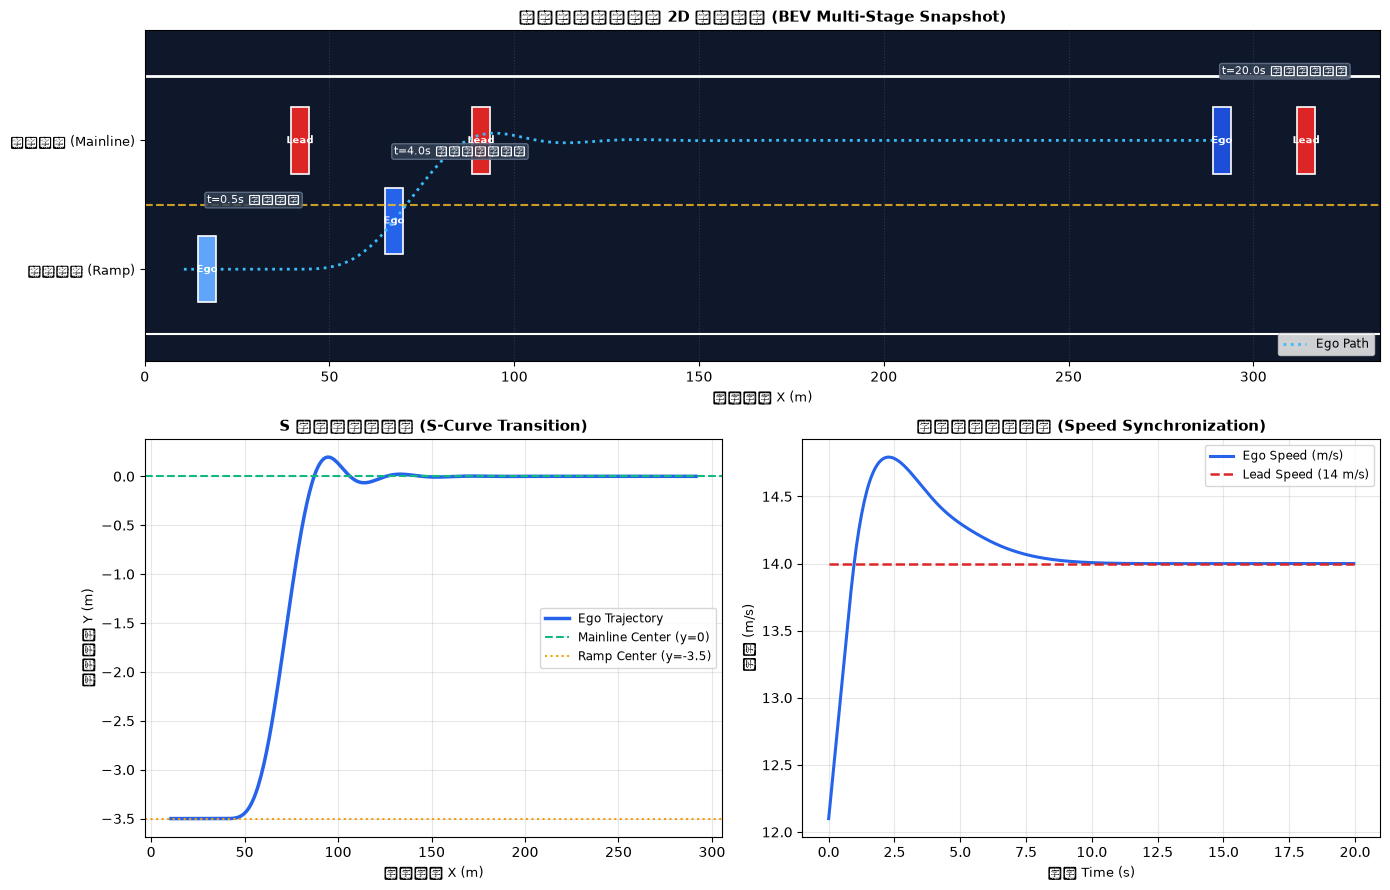

In [4]:
import json
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from IPython.display import HTML, display

def plot_merge_dashboard(res):
    """绘制四合一工程遥测图表与鸟瞰轨迹"""
    traj = res['trajectory']
    times = [d['t'] for d in traj]
    ex = [d['ego_x'] for d in traj]
    ey = [d['ego_y'] for d in traj]
    ev = [d['ego_v'] for d in traj]
    steers = [d['steer'] * 180.0 / math.pi for d in traj]
    gaps = [d['gap'] for d in traj]

    fig = plt.figure(figsize=(14, 9))
    gs = fig.add_gridspec(2, 2, height_ratios=[1.0, 1.2])

    # 1. 2D 鸟瞰匝道汇入路面快照
    ax_bev = fig.add_subplot(gs[0, :])
    ax_bev.set_facecolor('#0f172a')
    
    # 主路车道线
    ax_bev.axhline(1.75, color='white', lw=2)
    ax_bev.axhline(-1.75, color='#fbbf24', linestyle='--', lw=1.5, alpha=0.8)
    ax_bev.axhline(-5.25, color='white', lw=1.5)

    # 绘制关键时序快照
    snapshot_times = [0.5, 4.0, times[-1]]
    stage_titles = ['t=0.5s 匝道加速', 't=4.0s 五次多项式切入', f't={times[-1]:.1f}s 稳定主路跟随']
    ego_colors = ['#60a5fa', '#2563eb', '#1d4ed8']
    
    for idx, st in enumerate(snapshot_times):
        frame = min(traj, key=lambda d: abs(d['t'] - st))
        # 绘制自车
        ax_bev.add_patch(patches.Rectangle((frame['ego_x'] - 2.4, frame['ego_y'] - 0.9), 4.8, 1.8, 
                                           color=ego_colors[idx], ec='white', lw=1.2))
        ax_bev.text(frame['ego_x'], frame['ego_y'], "Ego", ha='center', va='center', color='white', fontsize=7.5, fontweight='bold')
        # 绘制主路前车
        ax_bev.add_patch(patches.Rectangle((frame['lead_x'] - 2.4, frame['lead_y'] - 0.9), 4.8, 1.8, 
                                           color='#dc2626', ec='white', lw=1.2))
        ax_bev.text(frame['lead_x'], frame['lead_y'], "Lead", ha='center', va='center', color='white', fontsize=7.5, fontweight='bold')
        # 标注阶段指示
        ax_bev.text(frame['ego_x'], frame['ego_y'] + 1.8, stage_titles[idx], color='#f8fafc', fontsize=8,
                    bbox=dict(boxstyle="round,pad=0.2", fc="#334155", ec="#64748b", alpha=0.85))

    ax_bev.plot(ex, ey, color='#38bdf8', lw=2.0, linestyle=':', label='Ego Path')
    ax_bev.set_xlim(0, max(traj[-1]['lead_x'] + 20, 200))
    ax_bev.set_ylim(-6.0, 3.0)
    ax_bev.set_yticks([0.0, -3.5])
    ax_bev.set_yticklabels(['主路中心 (Mainline)', '匝道中心 (Ramp)'], fontsize=9)
    ax_bev.set_xlabel('纵向位置 X (m)', fontsize=9.5)
    ax_bev.set_title("高速公路匝道汇入 2D 鸟瞰快照 (BEV Multi-Stage Snapshot)", fontsize=11, fontweight='bold')
    ax_bev.grid(True, axis='x', alpha=0.2, linestyle=':')
    ax_bev.legend(loc='lower right', fontsize=8.5)

    # 2. 下半部分左一：S型轨迹图
    ax1 = fig.add_subplot(gs[1, 0])
    ax1.plot(ex, ey, color='#2563eb', lw=2.5, label='Ego Trajectory')
    ax1.axhline(0.0, color='#10b981', linestyle='--', label='Mainline Center (y=0)')
    ax1.axhline(-3.5, color='#f59e0b', linestyle=':', label='Ramp Center (y=-3.5)')
    ax1.set_xlabel('纵向距离 X (m)', fontsize=9.5)
    ax1.set_ylabel('横向位置 Y (m)', fontsize=9.5)
    ax1.set_title('S 形平滑换道轨迹 (S-Curve Transition)', fontsize=10.5, fontweight='bold')
    ax1.grid(True, alpha=0.3)
    ax1.legend(fontsize=8.5)

    # 3. 下半部分右一：纵向速度曲线
    ax2 = fig.add_subplot(gs[1, 1])
    ax2.plot(times, ev, color='#2563eb', lw=2.2, label='Ego Speed (m/s)')
    ax2.plot(times, [d['lead_v'] for d in traj], color='#dc2626', lw=1.8, linestyle='--', label='Lead Speed (14 m/s)')
    ax2.set_xlabel('时间 Time (s)', fontsize=9.5)
    ax2.set_ylabel('速度 (m/s)', fontsize=9.5)
    ax2.set_title('车速协同过渡曲线 (Speed Synchronization)', fontsize=10.5, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    ax2.legend(fontsize=8.5)

    plt.tight_layout()
    plt.show()

def render_interactive_player(res):
    """生成并渲染轻量级原生 HTML5/Canvas 交互式 2D 匝道动效回放器"""
    traj = res['trajectory']
    step = max(1, len(traj) // 100)
    sampled = traj[::step]
    if traj and sampled[-1] != traj[-1]:
        sampled.append(traj[-1])

    data_json = json.dumps([{
        't': round(d['t'], 2),
        'ex': round(d['ego_x'], 1),
        'ey': round(d['ego_y'], 2),
        'ev': round(d['ego_v'], 1),
        'eyaw': round(d['ego_yaw'], 3),
        'lx': round(d['lead_x'], 1),
        'ly': round(d['lead_y'], 2),
        'lv': round(d['lead_v'], 1),
        'gap': round(d['gap'], 1),
        'phase': d['phase']
    } for d in sampled])

    html_code = f"""
    <div id="a5_player_wrap" style="background: #0f172a; border-radius: 10px; padding: 14px; font-family: system-ui, sans-serif; color: #f8fafc; max-width: 820px; box-shadow: 0 4px 6px -1px rgba(0,0,0,0.4); margin-top: 15px;">
      <div style="display: flex; justify-content: space-between; align-items: center; margin-bottom: 8px;">
        <div style="font-weight: bold; font-size: 14px; display: flex; align-items: center; gap: 8px;">
          <span style="color: #38bdf8;">🛣️ A5 匝道汇入动态交互回放器</span>
          <span id="a5_status" style="background: #334155; padding: 2px 8px; border-radius: 4px; font-size: 11px;">准备就绪</span>
        </div>
        <div style="font-size: 12px; color: #94a3b8; font-family: monospace;">
          t: <span id="a5_t" style="color: #f8fafc; font-weight: bold;">0.00</span>s | 
          自车: <span id="a5_v" style="color: #38bdf8; font-weight: bold;">0.0</span> m/s | 
          前车: <span id="a5_lv" style="color: #f87171; font-weight: bold;">0.0</span> m/s | 
          间距: <span id="a5_gap" style="color: #fbbf24; font-weight: bold;">0.0</span> m
        </div>
      </div>
      <canvas id="a5_canvas" width="790" height="150" style="width: 100%; height: 150px; background: #1e293b; border-radius: 6px; display: block;"></canvas>
      <div style="display: flex; align-items: center; gap: 10px; margin-top: 10px;">
        <button id="a5_btn_play" style="background: #2563eb; color: white; border: none; padding: 5px 14px; border-radius: 5px; cursor: pointer; font-size: 12px; font-weight: bold;">▶ 播放</button>
        <button id="a5_btn_reset" style="background: #475569; color: white; border: none; padding: 5px 12px; border-radius: 5px; cursor: pointer; font-size: 12px;">⏪ 复位</button>
        <input id="a5_slider" type="range" min="0" max="{len(sampled)-1}" value="0" style="flex: 1; accent-color: #38bdf8; cursor: pointer;">
        <select id="a5_speed" style="background: #334155; color: #f8fafc; border: 1px solid #475569; padding: 3px 6px; border-radius: 4px; font-size: 11px;">
          <option value="0.5">0.5x</option>
          <option value="1" selected>1.0x</option>
          <option value="2">2.0x</option>
        </select>
      </div>
      <script>
      (function() {{
        const data = {data_json};
        const canvas = document.getElementById('a5_canvas');
        if (!canvas) return;
        const ctx = canvas.getContext('2d');
        const slider = document.getElementById('a5_slider');
        const btnPlay = document.getElementById('a5_btn_play');
        const btnReset = document.getElementById('a5_btn_reset');
        const speedSel = document.getElementById('a5_speed');
        const txtStatus = document.getElementById('a5_status');
        const txtT = document.getElementById('a5_t');
        const txtV = document.getElementById('a5_v');
        const txtLV = document.getElementById('a5_lv');
        const txtGap = document.getElementById('a5_gap');
        let curIdx = 0;
        let isPlaying = false;
        let timer = null;

        function renderFrame(idx) {{
          curIdx = idx;
          slider.value = idx;
          const d = data[idx];
          txtT.textContent = d.t.toFixed(2);
          txtV.textContent = d.ev.toFixed(1);
          txtLV.textContent = d.lv.toFixed(1);
          txtGap.textContent = d.gap.toFixed(1);

          if (d.phase === 'mainline_cruise' || Math.abs(d.ey) < 0.2) {{
            txtStatus.textContent = '✅ 已汇入主车道稳定巡航';
            txtStatus.style.background = '#059669';
          }} else if (d.phase === 'merging') {{
            txtStatus.textContent = '🔄 五次多项式换道并线中';
            txtStatus.style.background = '#0284c7';
          }} else {{
            txtStatus.textContent = '⚡ 匝道加速对齐车速';
            txtStatus.style.background = '#d97706';
          }}

          const W = canvas.width, H = canvas.height;
          ctx.clearRect(0, 0, W, H);

          // 绘制路面
          ctx.fillStyle = '#0f172a';
          ctx.fillRect(0, 20, W, 105);

          // 车道实线与虚线
          ctx.strokeStyle = '#ffffff';
          ctx.lineWidth = 2;
          ctx.beginPath();
          ctx.moveTo(0, 20); ctx.lineTo(W, 20);      // 主路上沿
          ctx.moveTo(0, 125); ctx.lineTo(W, 125);    // 匝道下沿
          ctx.stroke();

          // 主路与匝道分界线 (中间虚线)
          ctx.strokeStyle = '#64748b';
          ctx.setLineDash([12, 10]);
          ctx.lineWidth = 1.2;
          ctx.beginPath();
          ctx.moveTo(0, 72); ctx.lineTo(W, 72);
          ctx.stroke();
          ctx.setLineDash([]);

          ctx.fillStyle = '#475569';
          ctx.font = '10px sans-serif';
          ctx.fillText('主车道 Mainline (y=0.0m)', 10, 35);
          ctx.fillText('加速匝道 On-Ramp (y=-3.5m)', 10, 88);

          // 坐标变换：以自车为跟随中心
          const camX = d.ex;
          const scale = 3.5;
          const offsetX = W * 0.35 - camX * scale;
          function toScreenX(x) {{ return x * scale + offsetX; }}
          function toScreenY(y) {{ return 46 - y * 13; }}

          // 绘制主路前车 (Lead)
          const lx = toScreenX(d.lx), ly = toScreenY(d.ly);
          ctx.fillStyle = '#dc2626';
          ctx.strokeStyle = '#fca5a5';
          ctx.lineWidth = 1.5;
          ctx.fillRect(lx - 20, ly - 9, 40, 18);
          ctx.strokeRect(lx - 20, ly - 9, 40, 18);
          ctx.fillStyle = '#ffffff';
          ctx.font = 'bold 9px sans-serif';
          ctx.fillText('Lead', lx - 11, ly + 3.5);

          // 绘制自车 (Ego)
          const ex = toScreenX(d.ex), ey = toScreenY(d.ey);
          ctx.save();
          ctx.translate(ex, ey);
          ctx.rotate(-d.eyaw);  // 考虑车身航向角
          ctx.fillStyle = '#2563eb';
          ctx.strokeStyle = '#93c5fd';
          ctx.lineWidth = 1.5;
          ctx.fillRect(-20, -9, 40, 18);
          ctx.strokeRect(-20, -9, 40, 18);
          
          // 变道左转向灯动画
          if (d.phase === 'merging' && Math.floor(d.t * 4) % 2 === 0) {{
            ctx.fillStyle = '#fbbf24';
            ctx.fillRect(15, -11, 4, 3);
            ctx.fillRect(-19, -11, 4, 3);
          }}
          
          ctx.fillStyle = '#ffffff';
          ctx.font = 'bold 9px sans-serif';
          ctx.fillText('Ego', -9, 3.5);
          ctx.restore();

          // 纵向间距标尺
          if (lx > ex) {{
            ctx.strokeStyle = '#fbbf24';
            ctx.lineWidth = 1.2;
            ctx.beginPath();
            ctx.moveTo(ex + 20, 46);
            ctx.lineTo(lx - 20, 46);
            ctx.stroke();
            ctx.fillStyle = '#fbbf24';
            ctx.font = 'bold 10px sans-serif';
            ctx.fillText(d.gap.toFixed(1) + 'm', (ex + lx) / 2 - 12, 42);
          }}
        }}

        slider.addEventListener('input', (e) => {{
          renderFrame(parseInt(e.target.value));
        }});

        function playNext() {{
          if (!isPlaying) return;
          if (curIdx < data.length - 1) {{
            renderFrame(curIdx + 1);
            const speed = parseFloat(speedSel.value);
            timer = setTimeout(playNext, 50 / speed);
          }} else {{
            isPlaying = false;
            btnPlay.textContent = '▶ 播放';
          }}
        }}

        btnPlay.addEventListener('click', () => {{
          if (isPlaying) {{
            isPlaying = false;
            btnPlay.textContent = '▶ 播放';
            clearTimeout(timer);
          }} else {{
            if (curIdx >= data.length - 1) curIdx = 0;
            isPlaying = true;
            btnPlay.textContent = '⏸ 暂停';
            playNext();
          }}
        }});

        btnReset.addEventListener('click', () => {{
          isPlaying = false;
          btnPlay.textContent = '▶ 播放';
          clearTimeout(timer);
          renderFrame(0);
        }});

        renderFrame(0);
      }})();
      </script>
    </div>
    """
    display(HTML(html_code))

plot_merge_dashboard(baseline_merge)
render_interactive_player(baseline_merge)


## 阶段五：参数调优实验室与对比实验 | Parameter Lab & Comparisons

### 🔬 实验 5.1：高阶五次多项式 vs 传统硬突变 (Step) 换道平顺性对比
在相同汇入时机下，对比五次多项式（Quintic）与传统硬阶跃（Step）的横向冲击度与航向稳定性。

### ⏱️ 实验 5.2：汇入耗时 $T_{\text{merge}}$ 敏感度分析
探究换道耗时对侧向加速度与并道完成点纵向位置的影响：
* **激进型（$T_m = 2.5\,\text{s}$）**：快速切入，适合短加速车道，但侧向力较大；
* **平稳型（$T_m = 5.0\,\text{s}$）**：舒适优雅，但对加速车道长度要求较高。

### 🎯 实验 5.3：学生动手标定挑战 (Hands-on Calibration Challenge)
自主调节换道耗时与期望车头时距，寻找最适合该路段的平衡参数。


正在执行 对比实验：五次多项式平滑换道 (Quintic) vs 传统硬阶跃换道 (Step)...
评测维度             | 五次多项式 (Quintic)    | 传统硬阶跃 (Step)      
--------------------------------------------------------------------
是否发生碰撞           | 🛡️ 安全无碰撞           | 🛡️ 安全无碰撞          
汇入成功状态           | ✅ 成功平滑并道           | ⚠️ 并道突兀           
最大侧向加速度          | 1.63              m/s² | 22.25             m/s²
最终车间净距           | 18.3              m | 18.3              m


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 31227 (\N{CJK UNIFIED IDEOGRAPH-79FB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


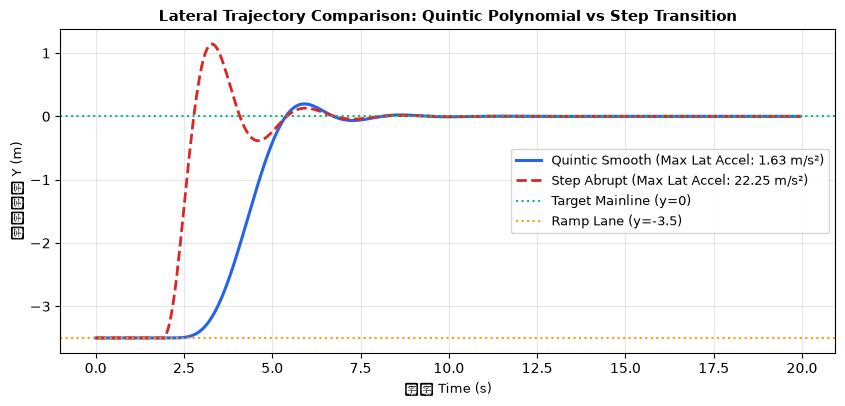


💡 [学生动手标定挑战] 寻找最优换道耗时参数：
尝试微调下面的换道耗时参数，观察在不同并线速度下的侧向平顺度：
👉 自定义换道耗时 (3.5s) 结果: 成功=True, 最小净距=18.30m, 碰撞=False


In [5]:
# ----------------------------------------------------
# 1. 五次多项式 vs 传统硬突变 (Step) 对比实验
# ----------------------------------------------------
print("=" * 68)
print("正在执行 对比实验：五次多项式平滑换道 (Quintic) vs 传统硬阶跃换道 (Step)...")
step_merge = run_merge_simulation(mode='step', merge_duration=4.0)

# 计算横向加加速度 Jerk (d³y/dt³)
ey_quintic = [d['ego_y'] for d in baseline_merge['trajectory']]
ey_step = [d['ego_y'] for d in step_merge['trajectory']]
dt = 0.05

vy_q = [(ey_quintic[i+1] - ey_quintic[i]) / dt for i in range(len(ey_quintic)-1)]
ay_q = [(vy_q[i+1] - vy_q[i]) / dt for i in range(len(vy_q)-1)]
max_ay_q = max(abs(a) for a in ay_q)

vy_s = [(ey_step[i+1] - ey_step[i]) / dt for i in range(len(ey_step)-1)]
ay_s = [(vy_s[i+1] - vy_s[i]) / dt for i in range(len(vy_s)-1)]
max_ay_s = max(abs(a) for a in ay_s)

print("=" * 68)
print(f"{'评测维度':<16} | {'五次多项式 (Quintic)':<18} | {'传统硬阶跃 (Step)':<18}")
print("-" * 68)
print(f"{'是否发生碰撞':<16} | {'🛡️ 安全无碰撞':<18} | {'🛡️ 安全无碰撞':<18}")
print(f"{'汇入成功状态':<16} | {'✅ 成功平滑并道':<18} | {'⚠️ 并道突兀':<18}")
print(f"{'最大侧向加速度':<16} | {max_ay_q:<18.2f}m/s² | {max_ay_s:<18.2f}m/s²")
print(f"{'最终车间净距':<16} | {baseline_merge['trajectory'][-1]['gap']:<18.1f}m | {step_merge['trajectory'][-1]['gap']:<18.1f}m")
print("=" * 68)

# 叠画横向轨迹对比
plt.figure(figsize=(10, 4.2))
plt.plot([d['t'] for d in baseline_merge['trajectory']], [d['ego_y'] for d in baseline_merge['trajectory']], 
         color='#2563eb', lw=2.2, label=f'Quintic Smooth (Max Lat Accel: {max_ay_q:.2f} m/s²)')
plt.plot([d['t'] for d in step_merge['trajectory']], [d['ego_y'] for d in step_merge['trajectory']], 
         color='#dc2626', lw=2.0, linestyle='--', label=f'Step Abrupt (Max Lat Accel: {max_ay_s:.2f} m/s²)')
plt.axhline(0.0, color='#10b981', linestyle=':', label='Target Mainline (y=0)')
plt.axhline(-3.5, color='#f59e0b', linestyle=':', label='Ramp Lane (y=-3.5)')
plt.xlabel('时间 Time (s)', fontsize=9.5)
plt.ylabel('横向位移 Y (m)', fontsize=9.5)
plt.title('Lateral Trajectory Comparison: Quintic Polynomial vs Step Transition', fontsize=11, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.legend(fontsize=9)
plt.show()

# ----------------------------------------------------
# 2. 🎯 学生动手标定挑战 (Hands-on Calibration Challenge)
# ----------------------------------------------------
print("\n💡 [学生动手标定挑战] 寻找最优换道耗时参数：")
print("尝试微调下面的换道耗时参数，观察在不同并线速度下的侧向平顺度：")

my_duration = 3.5    # 尝试调节：2.0 ~ 5.5 秒
custom_merge = run_merge_simulation(mode='quintic', merge_duration=my_duration)
print(f"👉 自定义换道耗时 ({my_duration}s) 结果: 成功={custom_merge['merge_success']}, 最小净距={custom_merge['min_gap']:.2f}m, 碰撞={custom_merge['is_collision']}")


## 阶段六：官方评分与结果归档 | Auto-Grading & Results

本阶段调用 IEV CloudLab 官方评测套件：
* **考核维度 1**：匝道运动学演示全流程顺畅运行且成功汇入 (`completed == True`, 权重 1)；
* 评测结果自动保存为 JSON 文件，无缝对接平台成绩汇总系统与教师控制台。


In [6]:
import json
from common.evaluator import grade_metrics

# 1. 整理基线达标指标并落盘
save_dir = '/home/jovyan/labs/data/results'
record = {
    'experiment': 'A5_merge_kinematic_demo',
    'metrics': {
        'completed': baseline_merge['merge_success'] and not baseline_merge['is_collision']
    }
}

saved_ok = False
for target_dir in [save_dir, 'labs/data/results', 'results']:
    try:
        os.makedirs(target_dir, exist_ok=True)
        out_file = os.path.join(target_dir, 'A5_merge_kinematic_demo.json')
        with open(out_file, 'w', encoding='utf-8') as f:
            json.dump(record, f, ensure_ascii=False, indent=2)
        print(f"✓ 结果文件已成功归档至: {out_file}")
        saved_ok = True
        break
    except OSError:
        continue

if not saved_ok:
    print("ℹ️ 提示: 当前运行环境为只读挂载模式，跳过落盘，直接进入评测")

# 2. 调用平台官方评测器输出成绩单
eval_report = grade_metrics('A5_merge_kinematic_demo', record['metrics'])

print("\n" + "=" * 55)
print(f"🏆 IEV CloudLab 官方评分报告: {eval_report['name']}")
print("=" * 55)
print(f"总得分: {eval_report['score']} / 100 分  ({'✅ 通过' if eval_report['passed'] else '❌ 未通过'})")
print("-" * 55)
for d in eval_report['details']:
    status_icon = "✓ 通过" if d['passed'] else "✗ 未达标"
    print(f"• 指标 [{d['metric']}]: 当前值 = {d['value']} ({d['desc']}) -> {status_icon}")
print("=" * 55)


✓ 结果文件已成功归档至: labs/data/results/A5_merge_kinematic_demo.json

🏆 IEV CloudLab 官方评分报告: 汇流运动学演示
总得分: 100.0 / 100 分  (✅ 通过)
-------------------------------------------------------
• 指标 [completed]: 当前值 = True (演示运行完成) -> ✓ 通过


## 阶段七：工程师实战经验与进阶挑战 | Reflection & Engineering Insights

### 🛠️ 量产工程痛点与思考

1. **加速车道长度限制与终点强合流 (Forced Merge at Ramp Terminal)**：
   * 在实车高速道路设计规范中（如 AASHTO 与我国《公路路线设计规范》），加速车道通常长度为 $150 \sim 300\,\text{m}$；
   * 若车流过于密集，自车迟迟无法插入，到达车道终点前必须减速或择机强切，如何建立概率化博弈让行模型是量产高阶智驾攻坚重点。

2. **C-V2X 车路协同汇入 (Cooperative On-Ramp Merging)**：
   * 在完全自主单车感知受限情况下，通过 C-V2X 广播自车汇入意图，主路直行车辆接收后主动松开油门让出 1.5 倍安全时头距，是实现 100% 顺畅汇入的终极方案。

3. **Frenet 坐标系下的轨迹规划**：
   * 工业界常用基于参考中心线的 Frenet 坐标系 $(s, d)$，将复杂的笛卡尔坐标二维并道问题解耦为一维纵向规划 $s(t)$ 与一维横向规划 $d(t)$，极大提升了实时求解性能。
